<a href="https://colab.research.google.com/github/MallelaAsrith/Skin-Cancer-Classification/blob/main/Skin_Cancer_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q kaggle pandas numpy matplotlib seaborn tensorflow

In [1]:
from google.colab import files
uploaded = files.upload()

Saving kaggle (1).json to kaggle (1).json


In [2]:
import os
import shutil
import json

filename = list(uploaded.keys())[0]

os.makedirs('/root/.kaggle', exist_ok=True)

shutil.copy(filename, '/root/.kaggle/kaggle.json')

os.chmod('/root/.kaggle/kaggle.json', 0o600)

print("Kaggle setup successful!")

Kaggle setup successful!


In [3]:
!mkdir -p /content/data

!kaggle datasets download \
-d kmader/skin-cancer-mnist-ham10000 \
-p /content/data \
--unzip

Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [00:51<00:00, 108MB/s]



In [4]:
import os

print("Files inside data folder:")

for root, dirs, files in os.walk("/content/data"):
    for file in files[:10]:
        print(os.path.join(root, file))

Files inside data folder:
/content/data/hmnist_28_28_RGB.csv
/content/data/hmnist_8_8_RGB.csv
/content/data/hmnist_28_28_L.csv
/content/data/HAM10000_metadata.csv
/content/data/hmnist_8_8_L.csv
/content/data/ham10000_images_part_2/ISIC_0030019.jpg
/content/data/ham10000_images_part_2/ISIC_0032413.jpg
/content/data/ham10000_images_part_2/ISIC_0030791.jpg
/content/data/ham10000_images_part_2/ISIC_0031679.jpg
/content/data/ham10000_images_part_2/ISIC_0033200.jpg
/content/data/ham10000_images_part_2/ISIC_0030407.jpg
/content/data/ham10000_images_part_2/ISIC_0032034.jpg
/content/data/ham10000_images_part_2/ISIC_0031815.jpg
/content/data/ham10000_images_part_2/ISIC_0033670.jpg
/content/data/ham10000_images_part_2/ISIC_0031206.jpg
/content/data/HAM10000_images_part_2/ISIC_0030019.jpg
/content/data/HAM10000_images_part_2/ISIC_0032413.jpg
/content/data/HAM10000_images_part_2/ISIC_0030791.jpg
/content/data/HAM10000_images_part_2/ISIC_0031679.jpg
/content/data/HAM10000_images_part_2/ISIC_0033200.

In [5]:
import pandas as pd
import os

metadata = pd.read_csv(
    "/content/data/HAM10000_metadata.csv"
)

print("Dataset loaded successfully!")
print("Dataset shape:", metadata.shape)

print("\nFirst 5 rows:")
print(metadata.head())

Dataset loaded successfully!
Dataset shape: (10015, 7)

First 5 rows:
     lesion_id      image_id   dx dx_type   age   sex localization
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear


In [6]:
print("Skin disease categories:")

print(metadata["dx"].value_counts())

Skin disease categories:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [7]:
print("Dataset information:")

print(metadata.info())

print("\nMissing values:")
print(metadata.isnull().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  object 
 1   image_id      10015 non-null  object 
 2   dx            10015 non-null  object 
 3   dx_type       10015 non-null  object 
 4   age           9958 non-null   float64
 5   sex           10015 non-null  object 
 6   localization  10015 non-null  object 
dtypes: float64(1), object(6)
memory usage: 547.8+ KB
None

Missing values:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64


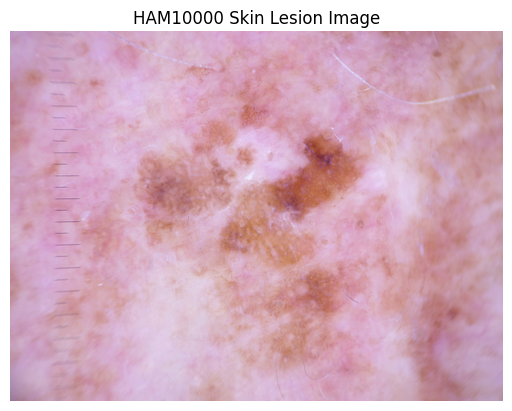

In [8]:
import matplotlib.pyplot as plt
from PIL import Image
import os

image_id = metadata.iloc[0]["image_id"]

image_path = (
    "/content/data/HAM10000_images_part_1/"
    + image_id + ".jpg"
)

img = Image.open(image_path)

plt.imshow(img)
plt.title("HAM10000 Skin Lesion Image")
plt.axis("off")
plt.show()

In [9]:
import glob
import os

image_paths = glob.glob(
    "/content/data/HAM10000_images_part_*/*.jpg"
)

image_dict = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_paths
}

metadata["path"] = metadata["image_id"].map(image_dict)

print("Total images:", len(image_paths))
print("Matched images:", metadata["path"].notna().sum())
print(metadata[["image_id", "dx", "path"]].head())

Total images: 10015
Matched images: 10015
       image_id   dx                                               path
0  ISIC_0027419  bkl  /content/data/HAM10000_images_part_1/ISIC_0027...
1  ISIC_0025030  bkl  /content/data/HAM10000_images_part_1/ISIC_0025...
2  ISIC_0026769  bkl  /content/data/HAM10000_images_part_1/ISIC_0026...
3  ISIC_0025661  bkl  /content/data/HAM10000_images_part_1/ISIC_0025...
4  ISIC_0031633  bkl  /content/data/HAM10000_images_part_2/ISIC_0031...


In [10]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

metadata["label"] = le.fit_transform(metadata["dx"])

print("Disease labels:")
for i, name in enumerate(le.classes_):
    print(i, "=", name)

Disease labels:
0 = akiec
1 = bcc
2 = bkl
3 = df
4 = mel
5 = nv
6 = vasc


In [11]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    metadata,
    test_size=0.2,
    random_state=42,
    stratify=metadata["label"]
)

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

Training samples: 8012
Testing samples: 2003


In [12]:
import tensorflow as tf
import numpy as np

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [14]:
IMG_SIZE = 128
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.image.decode_jpeg(
        image, channels=3
    )

    image = tf.image.resize(
        image, [IMG_SIZE, IMG_SIZE]
    )

    image = image / 255.0

    return image, label

In [15]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["path"].values, train_df["label"].values)
)

train_ds = train_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.batch(BATCH_SIZE).prefetch(
    tf.data.AUTOTUNE
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["path"].values, test_df["label"].values)
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(BATCH_SIZE).prefetch(
    tf.data.AUTOTUNE
)

print("Training and testing datasets prepared!")

Training and testing datasets prepared!


In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

model = Sequential([
    Conv2D(32, (3,3), activation='relu',
           input_shape=(128,128,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(7, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,543 (12.61 MB)

 Trainable params: 3,305,543 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [18]:
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=10
)

Epoch 1/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 79s 274ms/step - accuracy: 0.6655 - loss: 1.0518 - val_accuracy: 0.6695 - val_loss: 0.9683
Epoch 2/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 41s 163ms/step - accuracy: 0.6711 - loss: 0.9647 - val_accuracy: 0.6710 - val_loss: 0.8894
Epoch 3/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 41s 162ms/step - accuracy: 0.6782 - loss: 0.8912 - val_accuracy: 0.6755 - val_loss: 0.8533
Epoch 4/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 44s 175ms/step - accuracy: 0.6838 - loss: 0.8510 - val_accuracy: 0.6805 - val_loss: 0.8350
Epoch 5/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 79s 162ms/step - accuracy: 0.6950 - loss: 0.8147 - val_accuracy: 0.6885 - val_loss: 0.8384
Epoch 6/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 43s 171ms/step - accuracy: 0.7106 - loss: 0.7849 - val_accuracy: 0.6975 - val_loss: 0.8907
Epoch 7/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 41s 162ms/step - accuracy: 0.7128 - loss: 0.7587 - val_accuracy: 0.6965 - val_loss: 0.8194
Epoch 8/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 44s 174ms/step - accuracy: 0.7244 - loss: 0

In [19]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 141ms/step - accuracy: 0.7244 - loss: 0.8093
Test Loss: 0.8093466758728027
Test Accuracy: 72.44133949279785 %


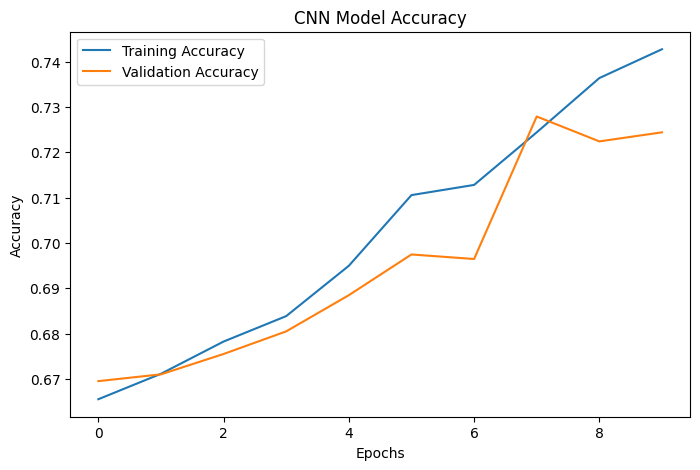

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [21]:
model.save('/content/HAM10000_CNN_Model.keras')

print("Model saved successfully!")

Model saved successfully!


In [23]:
from google.colab import files

files.download('/content/HAM10000_CNN_Model.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>